# Mini-Project 3 Lake Victoria Fish Stock & Export Risk Model

**Scenario.** A fish export cooperative in Jinja wants to know (a) whether its harvesting rate is sustainable and (b) how risky its revenue is. The previous version of this question modelled stock with Fibonacci numbers and flagged risk when revenue variance exceeded 50,000. We build a more defensible model and explain why the old approach is flawed.

**Data provenance.** Everything here is a **model with illustrative parameters** from the assignment (r = 0.4, K = 10,000 t, N₀ = 4,000 t, price starting at UGX 12,000/kg with bounds 9,000–16,000). The price-walk step size (SD UGX 300/kg per week), the reflecting bounds, the risk tolerances and the closed-season weeks are our stated assumptions. No figure here is an observed Lake Victoria statistic.

**Units and timing (fixed for the whole notebook).**

| Quantity | Unit | Convention |
|---|---|---|
| Time step | week | $r$ and $h$ are **per-week** rates |
| Stock $N_t$, harvest $H_t$ | tonnes | $H_t = h\,N_t$, taken from the stock at the *start* of week $t$ |
| Price $P_t$ | UGX per kg | one price per week |
| Revenue $R_t$ | UGX per week | $R_t = H_t \times 1{,}000\ \text{kg/t} \times P_t$ |
| Annual revenue | UGX per year | sum of 52 weekly revenues |

All reusable logic is in `src/fish_stock.py` (tested in `tests/test_fish_stock.py`).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import statistics
import numpy as np
import matplotlib.pyplot as plt

from src.fish_stock import (
    fibonacci, FishStock, PriceModel, RiskAssessor,
    weekly_revenue, monte_carlo_annual_revenue, value_at_risk, KG_PER_TONNE,
)

SEED = 2026
WEEKS = 52
N_PATHS = 1000
BASE_H = 0.10                       # base case for Tasks 2-5
HARVEST_RATES = [0.05, 0.10, 0.20, 0.30]
np.set_printoptions(precision=1, suppress=True, linewidth=110)

## 1. Baseline: Fibonacci "stock" (Task 1)

In [2]:
fib = fibonacci(15)
print("15 Fibonacci numbers:", fib)
print("Ratios F(n+1)/F(n):", np.round(fib[1:] / fib[:-1], 4))

15 Fibonacci numbers: [  1   1   2   3   5   8  13  21  34  55  89 144 233 377 610]
Ratios F(n+1)/F(n): [1.  2.  1.5 1.7 1.6 1.6 1.6 1.6 1.6 1.6 1.6 1.6 1.6 1.6]


**Why unbounded Fibonacci growth is biologically unrealistic.** The sequence grows without limit, by a factor approaching φ ≈ 1.618 per step, so after enough steps it exceeds any lake's capacity to feed and shelter fish. Real populations are limited by food, space, oxygen and predation: as density rises, growth slows towards a **carrying capacity**, which Fibonacci growth has no way to represent. The recurrence also has no deaths, no harvesting and no environmental variation, and it depends only on the two previous counts, not on how large the stock is relative to its habitat. Finally, its numbers are counts of breeding pairs in an idealised rabbit model, so applying them as "tonnes of fish" has no biological meaning.

## 2. `FishStock`: logistic growth with harvesting (Task 2)

$$N_{t+1} = N_t + r N_t\left(1 - \frac{N_t}{K}\right) - h N_t, \qquad r = 0.4,\ K = 10{,}000\ \text{t},\ N_0 = 4{,}000\ \text{t}.$$

Setting $N_{t+1} = N_t$ gives the steady state $N^* = K(1 - h/r)$, with weekly yield $hN^* = hK(1 - h/r)$. This is largest at $h = r/2$, where it equals the **maximum sustainable yield** $\text{MSY} = rK/4$.

In [3]:
stock = FishStock(r=0.4, K=10_000, n0=4_000)
base = stock.simulate(WEEKS, h=BASE_H)
print(stock)
print(f"Base case h = {BASE_H}: N(0) = {base.stock_tonnes[0]:,.0f} t, N(52) = {base.final_stock:,.1f} t, "
      f"total harvest = {base.total_harvest:,.0f} t")

# Hand check of week 0: harvest 0.1 x 4000 = 400 t; N(1) = 4000 + 0.4*4000*(1 - 0.4) - 400 = 4560 t
print(f"Week-0 check: harvest {base.harvest_tonnes[0]:.1f} t (hand: 400), N(1) = {base.stock_tonnes[1]:.1f} t (hand: 4560)")
print(f"Theory: equilibrium K(1 - h/r) = {stock.equilibrium(BASE_H):,.0f} t; MSY = rK/4 = {stock.msy:,.0f} t/week "
      f"at h = r/2 = {stock.msy_harvest_rate}")

FishStock(r=0.4, K=10,000 t, n0=4,000 t)
Base case h = 0.1: N(0) = 4,000 t, N(52) = 7,500.0 t, total harvest = 37,363 t
Week-0 check: harvest 400.0 t (hand: 400), N(1) = 4560.0 t (hand: 4560)
Theory: equilibrium K(1 - h/r) = 7,500 t; MSY = rK/4 = 1,000 t/week at h = r/2 = 0.2


## 3. `PriceModel` and weekly revenue (Task 3)

The price follows a seeded random walk: $P_0 = 12{,}000$, $P_{t+1} = P_t + \varepsilon_t$ with $\varepsilon_t \sim N(0, 300)$ UGX/kg. A step that would cross 9,000 or 16,000 is **reflected** back inside the band; clipping was rejected because it makes the price stick at a bound for several weeks, which distorts the variance.

In [4]:
price_model = PriceModel(start=12_000, step_sd=300, lower=9_000, upper=16_000)
prices = price_model.simulate(WEEKS, np.random.default_rng(SEED))
revenue = weekly_revenue(base.harvest_tonnes, prices)

print(price_model)
print(f"Price range over the year: {prices.min():,.0f} to {prices.max():,.0f} UGX/kg")
print(f"Week 0 revenue: {base.harvest_tonnes[0]:.0f} t x {KG_PER_TONNE:.0f} kg/t x {prices[0]:,.0f} UGX/kg "
      f"= UGX {revenue[0]:,.0f}  (hand: 400 x 1000 x 12,000 = 4,800,000,000)")
print(f"Annual revenue on this price path: UGX {revenue.sum():,.0f}")

PriceModel(start=12,000, step_sd=300, bounds=[9,000, 16,000] UGX/kg)
Price range over the year: 11,265 to 15,742 UGX/kg
Week 0 revenue: 400 t x 1000 kg/t x 12,000 UGX/kg = UGX 4,800,000,000  (hand: 400 x 1000 x 12,000 = 4,800,000,000)
Annual revenue on this price path: UGX 458,467,469,765


## 4. Revenue statistics and the variance threshold (Task 4)

In [5]:
r_list = revenue.tolist()
mean, median = statistics.mean(r_list), statistics.median(r_list)
var, sd = statistics.variance(r_list), statistics.stdev(r_list)
print(f"Weekly revenue (h = {BASE_H}, one price path), UGX:")
print(f"  mean     {mean:>22,.0f}")
print(f"  median   {median:>22,.0f}")
print(f"  variance {var:>22,.3e}  (units: UGX squared)")
print(f"  SD       {sd:>22,.0f}")
print(f"  CV       {sd / mean:>22.3f}  (unitless)")
print(f"\nVariance / 50,000 = {var / 50_000:.3e}")
print(f"Same revenue measured in millions of UGX: variance = {statistics.variance([v / 1e6 for v in r_list]):,.1f} (UGX million squared), "
      f"CV = {statistics.stdev([v / 1e6 for v in r_list]) / statistics.mean([v / 1e6 for v in r_list]):.3f}")

h_list = base.harvest_tonnes.tolist()
print(f"\nCV of weekly harvest alone (no price risk at all): {statistics.stdev(h_list) / statistics.mean(h_list):.3f}")

Weekly revenue (h = 0.1, one price path), UGX:
  mean              8,816,682,111
  median            8,908,470,710
  variance              1.552e+18  (units: UGX squared)
  SD                1,245,877,560
  CV                        0.141  (unitless)

Variance / 50,000 = 3.104e+13
Same revenue measured in millions of UGX: variance = 1,552,210.9 (UGX million squared), CV = 0.141

CV of weekly harvest alone (no price risk at all): 0.107


**Why a raw variance threshold such as 50,000 is meaningless.** Variance is measured in the **square** of the data's units here UGX². Weekly revenue is in the billions of UGX, so its variance is of order $10^{18}$ UGX², more than $10^{13}$ times the threshold: under the old rule *every* realistic revenue series would be "risky", whatever its stability. The threshold is also not scale invariant: re-expressing the same revenue in millions of UGX shrinks the variance by a factor of $10^{12}$ and would then make it look "safe". A defensible measure must be unit free and relative to the size of revenue; the **coefficient of variation** (SD ÷ mean) is, and it is unchanged by the change of units above.

**A caution about this weekly CV.** Part of the weekly variation is not risk at all: the harvest itself rises predictably as the stock grows from 4,000 t towards equilibrium (the harvest-only CV above has no price uncertainty in it). That is why the risk rule below uses the spread of **annual** revenue across many simulated price paths, which isolates genuine price uncertainty.

## 5. `RiskAssessor`, Monte Carlo and 5 % VaR (Task 5)

**Risk rule (justified).** Under approximate normality, a 1-in-20 bad year is about $\mu - 1.645\sigma$, a shortfall of $1.645 \times \text{CV}$ below the expected annual revenue. *Stated assumption:* the cooperative can absorb a 1-in-20 shortfall of up to 10 % (**Low**), finds up to 20 % uncomfortable but manageable (**Moderate**), and anything larger is **High**. The thresholds follow: CV < 0.10/1.645 = 6.08 % is Low, CV < 0.20/1.645 = 12.16 % is Moderate, otherwise High.

**VaR definition.** The 5 % Value-at-Risk is reported as the **5th percentile of simulated annual revenue**: in 1 year out of 20, revenue is expected to be at or below this level.

In [6]:
assessor = RiskAssessor.from_shortfall_tolerance(low=0.10, high=0.20, z=1.645)
annual = monte_carlo_annual_revenue(base, price_model, n_paths=N_PATHS, seed=SEED)
result = assessor.assess(annual, level=0.05)

print(assessor)
print(f"Monte Carlo: {N_PATHS:,} price paths, h = {BASE_H}")
print(f"  mean annual revenue  UGX {result['mean']:,.0f}")
print(f"  SD                   UGX {result['sd']:,.0f}")
print(f"  CV                   {result['cv']:.2%}  -> risk class: {result['risk']}")
print(f"  5% VaR (5th pct)     UGX {result['var']:,.0f}  ({result['var'] / result['mean'] - 1:+.1%} vs mean)")
print(f"  normal approximation mean - 1.645 SD = UGX {result['mean'] - 1.645 * result['sd']:,.0f}")

RiskAssessor(Low < 6.08% <= Moderate < 12.16% <= High)
Monte Carlo: 1,000 price paths, h = 0.1
  mean annual revenue  UGX 449,117,731,324
  SD                   UGX 42,510,113,093
  CV                   9.47%  -> risk class: Moderate
  5% VaR (5th pct)     UGX 383,697,907,795  (-14.6% vs mean)
  normal approximation mean - 1.645 SD = UGX 379,188,595,286


The empirical 5th percentile is close to the normal approximation $\mu - 1.645\sigma$, which supports using that approximation to derive the thresholds. The risk class is **Moderate**: a 1-in-20 year would bring in roughly 15 % less than an average year.

## 6. Scenario analysis and MSY (Task 6)

For each harvest rate we simulate 52 weeks of stock and run the same 1,000 seeded price paths (common random numbers), so differences between scenarios come from harvesting, not from luck.

In [7]:
paths, summaries = {}, {}
print(f"MSY = rK/4 = {stock.msy:,.0f} t/week (= {stock.msy * WEEKS:,.0f} t/year) at h = {stock.msy_harvest_rate}\n")
header = (f"{'h':>5} {'Final stock':>12} {'Equilib.':>9} {'Harvest (t)':>12} {'Avg t/wk':>9} {'% of MSY':>9} "
          f"{'Sust. yield':>12} {'Mean revenue (UGX bn)':>22} {'CV':>6} {'Risk':>9} {'VaR 5% (UGX bn)':>16}")
print(header); print("-" * len(header))
for h in HARVEST_RATES:
    path = stock.simulate(WEEKS, h)
    rev = monte_carlo_annual_revenue(path, price_model, n_paths=N_PATHS, seed=SEED)
    s = assessor.assess(rev)
    paths[h], summaries[h] = path, {**s, "annual": rev}
    avg = path.total_harvest / WEEKS
    print(f"{h:5.2f} {path.final_stock:12,.0f} {stock.equilibrium(h):9,.0f} {path.total_harvest:12,.0f} {avg:9,.0f} "
          f"{avg / stock.msy:9.0%} {stock.sustainable_yield(h):12,.0f} {s['mean'] / 1e9:22,.1f} {s['cv']:6.1%} "
          f"{s['risk']:>9} {s['var'] / 1e9:16,.1f}")

MSY = rK/4 = 1,000 t/week (= 52,000 t/year) at h = 0.2

    h  Final stock  Equilib.  Harvest (t)  Avg t/wk  % of MSY  Sust. yield  Mean revenue (UGX bn)     CV      Risk  VaR 5% (UGX bn)
-----------------------------------------------------------------------------------------------------------------------------------
 0.05        8,750     8,750       21,715       418       42%          438                  261.0   9.5%  Moderate            222.8
 0.10        7,500     7,500       37,363       719       72%          750                  449.1   9.5%  Moderate            383.7
 0.20        5,000     5,000       50,872       978       98%        1,000                  611.5   9.3%  Moderate            524.0
 0.30        2,504     2,500       42,461       817       82%          750                  510.3   8.7%  Moderate            441.3


**Interpretation.**

* **h = 0.20 is the MSY harvest rate.** It holds the stock at $K/2 = 5{,}000$ t and yields about 1,000 t/week once settled, exactly $rK/4$. Its year-1 average is slightly below MSY only because the stock starts at 4,000 t rather than 5,000 t.
* **h = 0.30 is over-harvesting.** It is not a collapse (that needs $h \ge r = 0.4$), but it drives the stock down to 2,500 t and yields only 750 t/week in the long run — **less fish from a smaller stock** than h = 0.20, and less revenue. The higher catch early in the year comes from drawing down the stock, which cannot be repeated.
* **h = 0.05 and 0.10 are sustainable but under-use the stock**, leaving revenue on the table in exchange for a large buffer (8,750 and 7,500 t) against shocks the model does not include.
* **The CV-based risk class is Moderate in every scenario.** The class measures *price* risk, which is the same for all harvest rates, so it cannot detect over harvesting. Sustainability must be judged against MSY and the equilibrium stock, not by revenue volatility; a complete risk assessment needs both.

## 7. Charts (Task 7)

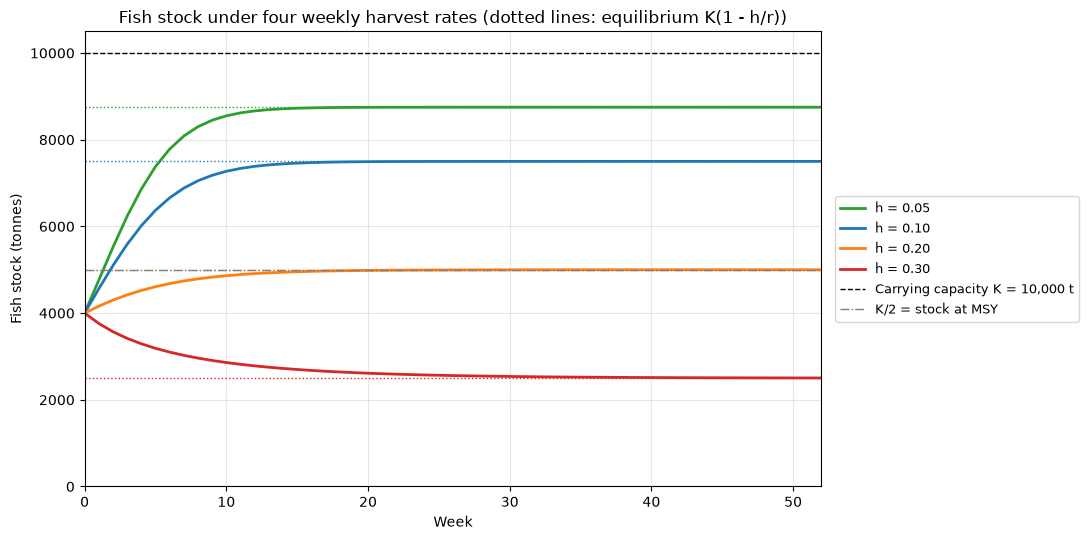

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.5))
weeks_axis = np.arange(WEEKS + 1)
colors = dict(zip(HARVEST_RATES, ["tab:green", "tab:blue", "tab:orange", "tab:red"]))
for h in HARVEST_RATES:
    ax.plot(weeks_axis, paths[h].stock_tonnes, color=colors[h], linewidth=2, label=f"h = {h:.2f}")
    ax.axhline(stock.equilibrium(h), color=colors[h], linestyle=":", linewidth=1)
ax.axhline(stock.K, color="black", linestyle="--", linewidth=1, label=f"Carrying capacity K = {stock.K:,.0f} t")
ax.axhline(stock.K / 2, color="grey", linestyle="-.", linewidth=1, label="K/2 = stock at MSY")
ax.set_xlabel("Week")
ax.set_ylabel("Fish stock (tonnes)")
ax.set_title("Fish stock under four weekly harvest rates (dotted lines: equilibrium K(1 - h/r))")
ax.set_xlim(0, WEEKS); ax.set_ylim(0, stock.K * 1.05)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Each trajectory settles at its own equilibrium within a few months because $r = 0.4$ per week is a very fast growth rate. Only h = 0.20 holds the stock at $K/2$, the level that maximises sustainable yield; h = 0.30 pulls the stock *below* that level.

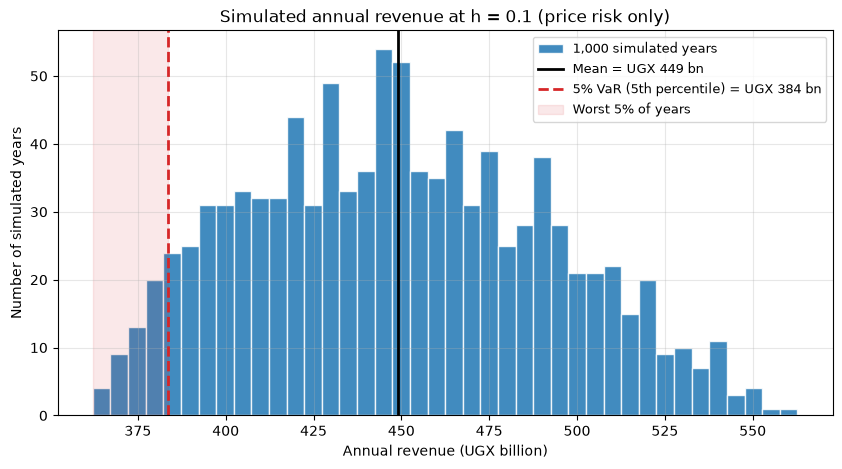

In [9]:
annual = summaries[BASE_H]["annual"]
var5 = summaries[BASE_H]["var"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(annual / 1e9, bins=40, color="tab:blue", edgecolor="white", alpha=0.85, label=f"{N_PATHS:,} simulated years")
ax.axvline(annual.mean() / 1e9, color="black", linewidth=2, label=f"Mean = UGX {annual.mean() / 1e9:,.0f} bn")
ax.axvline(var5 / 1e9, color="tab:red", linestyle="--", linewidth=2, label=f"5% VaR (5th percentile) = UGX {var5 / 1e9:,.0f} bn")
ax.axvspan(annual.min() / 1e9, var5 / 1e9, color="tab:red", alpha=0.1, label="Worst 5% of years")
ax.set_xlabel("Annual revenue (UGX billion)")
ax.set_ylabel("Number of simulated years")
ax.set_title(f"Simulated annual revenue at h = {BASE_H} (price risk only)")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

The histogram is roughly bell-shaped with a slight right skew (more room for unusually good years than unusually bad ones in this run). The red region is the worst 5 % of simulated years; the cooperative should plan its fixed costs and loan repayments so that it survives a year at the VaR level, not just an average year.

## 8. Extension: an 8-week closed season over 5 years

*Stated assumption:* no harvesting in weeks 12–19 of every year (8 weeks). The model has no seasonality, so the exact weeks barely matter here; in reality a closed season would be timed to protect spawning, which this model cannot represent. We simulate 5 years (260 weeks) with and without the closed season and use the same 1,000 seeded price paths for both, so the comparison isolates the effect of the closure.

In [10]:
YEARS, CLOSED = 5, range(12, 20)
weeks5 = YEARS * WEEKS
prices5 = price_model.simulate_paths(N_PATHS, weeks5, np.random.default_rng(SEED))

print(f"{'h':>5} {'5-yr revenue open (UGX bn)':>27} {'with closed season':>19} {'change':>8} "
      f"{'Year-5 harvest open (t)':>24} {'closed':>8} {'Final stock open/closed (t)':>28}")
ext = {}
for h in HARVEST_RATES:
    open_path = stock.simulate(weeks5, h)
    closed_path = stock.simulate(weeks5, h, closed_weeks=CLOSED)
    rev_open = weekly_revenue(open_path.harvest_tonnes, prices5).sum(axis=1).mean()
    rev_closed = weekly_revenue(closed_path.harvest_tonnes, prices5).sum(axis=1).mean()
    ext[h] = (open_path, closed_path)
    y5 = slice(4 * WEEKS, 5 * WEEKS)
    print(f"{h:5.2f} {rev_open / 1e9:27,.0f} {rev_closed / 1e9:19,.0f} {rev_closed / rev_open - 1:+8.1%} "
          f"{open_path.harvest_tonnes[y5].sum():24,.0f} {closed_path.harvest_tonnes[y5].sum():8,.0f} "
          f"{open_path.final_stock:13,.0f} / {closed_path.final_stock:,.0f}")

    h  5-yr revenue open (UGX bn)  with closed season   change  Year-5 harvest open (t)   closed  Final stock open/closed (t)
 0.05                       1,390               1,185   -14.8%                   22,750   19,411         8,750 / 8,750
 0.10                       2,384               2,058   -13.7%                   39,000   33,682         7,500 / 7,500
 0.20                       3,192               2,895    -9.3%                   52,000   47,165         5,000 / 5,002
 0.30                       2,446               2,621    +7.2%                   39,000   41,996         2,500 / 2,555


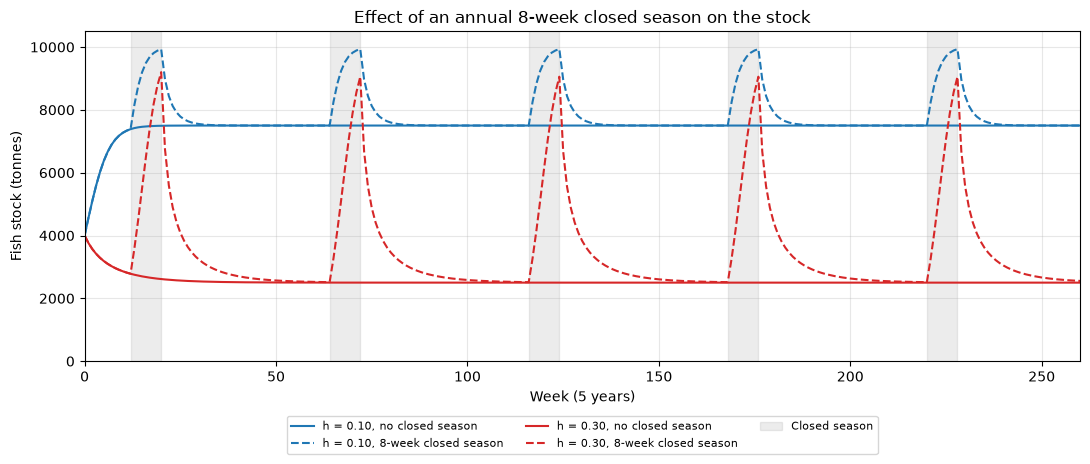

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.8))
w = np.arange(weeks5 + 1)
for h in (0.10, 0.30):
    open_path, closed_path = ext[h]
    ax.plot(w, open_path.stock_tonnes, color=colors[h], linewidth=1.5, label=f"h = {h:.2f}, no closed season")
    ax.plot(w, closed_path.stock_tonnes, color=colors[h], linestyle="--", linewidth=1.5, label=f"h = {h:.2f}, 8-week closed season")
for year in range(YEARS):
    ax.axvspan(year * WEEKS + 12, year * WEEKS + 20, color="grey", alpha=0.15, label="Closed season" if year == 0 else None)
ax.set_xlabel("Week (5 years)")
ax.set_ylabel("Fish stock (tonnes)")
ax.set_title("Effect of an annual 8-week closed season on the stock")
ax.set_ylim(0, stock.K * 1.05); ax.set_xlim(0, weeks5)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15)); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretation.** The closed season's effect depends on whether the cooperative is harvesting above or below the MSY rate:

* **At or below the MSY rate (h ≤ 0.20)** the closure **reduces** 5 year revenue (by roughly 9–15 %). The stock is already at or above $K/2$, so pausing harvests just forgoes catch; the stock rebounds towards $K$ during the closure, where growth is slow, and the extra fish are caught back only partly.
* **Above the MSY rate (h = 0.30)** the closure **increases** 5 year revenue (about +7 %). The over harvested stock is below $K/2$, where growth is fast, so the eight weeks of rest produce more fish than they cost.

The stock chart shows why: during each closure the stock climbs almost to the carrying capacity within eight weeks another sign that $r = 0.4$ per week is unrealistically fast and then falls back once harvesting resumes. So a closed season is a useful tool for an *over*-harvesting fishery, but for a cooperative already at or below MSY it is cheaper to set the right harvest rate. **Limitations:** the logistic model recovers within weeks because $r = 0.4$ per week is very fast; it has no age structure or spawning season, which is the main real reason for closed seasons; and prices are assumed unaffected by supply, whereas a closure might raise prices.

## 9. Findings & Limitations

*Word count: approximately 255.*

**Findings.** The cooperative's revenue is best served by harvesting at the maximum-sustainable yield rate, h = 0.20, which holds the stock at half the carrying capacity and yields about 1,000 tonnes a week. Raising the rate to 0.30 does not collapse the stock under this model, but it is counter-productive: it halves the stock and produces less fish and less revenue than h = 0.20. Rates of 0.05–0.10 are safe but forgo substantial revenue. Revenue risk from prices is Moderate in every scenario: a 1-in-20 year brings in about 15 % less than average. The old rule of flagging risk when variance exceeds 50,000 is meaningless, because variance is in UGX², of order 10¹⁸ here, and changes with the unit of currency; the coefficient of variation is unit free. An 8 week closed season helps only when the stock is over-harvested.

**Limitations.** The parameters are illustrative and imply implausible scale: r = 0.4 per week lets the stock recover within weeks, and the implied revenue, hundreds of billions of UGX a year, is far beyond a single cooperative. The CV-based risk class captures price risk only; it cannot see over-harvesting, which must be judged against MSY. Price is modelled as a bounded random walk independent of supply, so large harvests do not depress prices, and the step size and bounds are assumptions. The model is deterministic in stock: real fisheries face environmental shocks, illegal fishing and recruitment variability, so its "sustainable" rates are optimistic and should be treated as upper limits, ideally set below MSY to leave a safety margin.